# Frequency analysis (Beamforming) - Array Horizontal
1/3 octave bands
A check at each octave band of the direction of arrival accuracy of each method

How does accuracy vary with frequency

Using butterworth filters to separate recorded signals into 1/3 octave bands

No need to check accuracy at every angle here as the output should be the same no matter the angle, the array in relation to the source should always be symmetric.

This analysis should help us to determine at what frequencies these methods are viable

Seems as though beamforming results in a much narower working frequency range. 
Beamforming works differently on broadband signals compared to tonal signals, ****VERY IMPORTANT****
Broadband signals hve "More chance to get the DOA correct"
Tonal signals may be very accurate, depending on the frequency. But if the tone is outside the "Working frequency range" it can be way off.

At low frequencies, the signal is perceived by the receiver as planar due to the size of the array. Due to the wavelength of the sound compared to the size of the array, all signals are receiving roughly the same signal at the same time



In [1]:
import soundfile as sf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path    
from scipy.fft import fft, ifft
from scipy.optimize import brentq
import matplotlib.cm as cm
import pyroomacoustics as pra
import numpy as np
import soundfile as sf
from scipy.signal import butter, lfilter, freqz, sosfreqz, sosfiltfilt

import sys
sys.path.append("/Users/kevinbrennan/Desktop/Diploma/Project/Code/HATS_Code") 

from HATS_functions import gcc_phat, corr_to_itd

angles = ["-90", "-67.5", "-45", "-22.5", "0", "22.5", "45", "67.5", "90"]

height = 'H2'
source_angle = '45'
PathToFiles = f"../Audio_Files/Mic_Array/Horizontal/{source_angle}"

num_mics = 7
fs = 48000

recordings = {}

folder = Path(PathToFiles) 
if folder.is_dir():
    recordings[source_angle] = {
            '0': folder / "Untitled 1-270.wav",
            '1': folder / "Untitled 2-Audio.wav",
            '2': folder / "Untitled 3-Audio.wav",
            '3': folder / "Untitled 4-Audio.wav",
            '4': folder / "Untitled 5-Audio.wav",
            '5': folder / "Untitled 6-Audio.wav",
            '6': folder / "Untitled 7-Audio.wav",
            '7': folder / "Untitled 8-Audio.wav"
        }
else:
    print(f"Missing folder: {folder}")
        
r = 0.045
mic_angles_deg = [0, 60, 120, 180, 240, 300]

positions = [[0, 0, 0]]
for a in mic_angles_deg:
    theta = np.radians(a)
    positions.append([0, -r * np.sin(theta), r * np.cos(theta)])

mic_positions = np.array(positions).T

In [2]:
signals = []
for i in range(7):
    data, fs = sf.read(recordings[source_angle][str(i)])
    if data.ndim > 1:
        data = data.mean(axis=1)
    signals.append(data)

min_len = min(len(s) for s in signals)
signals = np.stack([s[:min_len] for s in signals])

# STFT
nfft = 256
hop = nfft // 2
X = pra.transform.stft.analysis(signals.T, L=nfft, hop=hop)
X = X.transpose(2, 1, 0)  

# SRP-PHAT
azimuth_grid = np.linspace(-np.pi/2, np.pi/2, 181)  
colatitude_grid = np.linspace(0, np.pi, 181) 

doa = pra.doa.algorithms['SRP'](mic_positions, fs, nfft, c=343, num_src=1, dim=3, azimuth=azimuth_grid, colatitude=colatitude_grid)
doa.locate_sources(X)

azimuth_deg = np.degrees(doa.azimuth_recon[0])
elevation_deg = 90 - np.degrees(doa.colatitude_recon[0])

def run_music_3d(recording_dict):
    signals = []
    for i in range(7):
        data, fs = sf.read(recording_dict[str(i)])
        if data.ndim > 1:
            data = data.mean(axis=1)
        signals.append(data)

    min_len = min(len(s) for s in signals)
    signals = np.stack([s[:min_len] for s in signals])

    nfft = 256
    hop = nfft // 2
    X = pra.transform.stft.analysis(signals.T, L=nfft, hop=hop)
    X = X.transpose(2, 1, 0)

    doa = pra.doa.algorithms['MUSIC'](
        mic_positions, fs, nfft, c=343, num_src=1)
    doa.locate_sources(X)
    return doa


third_octave_centres = [
    125, 160,
    200, 250, 315,
    400, 500, 630,
    800, 1000, 1250,
    1600, 2000, 2500,
    3150, 4000, 5000,
    6300, 8000, 10000,
    12500, 16000
]

def butter_bandpass_sos(lowcut, highcut, fs, order=4):
    sos = butter(order, [lowcut, highcut], btype='band', fs=fs, output='sos')
    return sos

def bandpass_third_octave(signal, fc, fs, order=2):
    low = fc / (2**(1/6))
    high = fc * (2**(1/6))
    high = min(high, fs/2 - 1)
    sos = butter(order, [low, high], btype='band', fs=fs, output='sos')
    return sosfiltfilt(sos, signal, axis=0)

def run_music_horizontal_filtered(recording_dict, fc):
    signals = []
    for i in range(7):
        data, fs = sf.read(recording_dict[str(i)])
        if data.ndim > 1:
            data = data.mean(axis=1)
        signals.append(bandpass_third_octave(data, fc, fs))

    min_len = min(len(s) for s in signals)
    signals = np.stack([s[:min_len] for s in signals])

    nfft = 256
    hop = nfft // 2
    X = pra.transform.stft.analysis(signals.T, L=nfft, hop=hop)
    X = X.transpose(2, 1, 0)

    doa = pra.doa.algorithms['MUSIC'](
        mic_positions, fs, nfft, c=343, num_src=1
    )
    doa.locate_sources(X)
    return doa

In [3]:
recordings

{'45': {'0': PosixPath('../Audio_Files/Mic_Array/Horizontal/45/Untitled 1-270.wav'),
  '1': PosixPath('../Audio_Files/Mic_Array/Horizontal/45/Untitled 2-Audio.wav'),
  '2': PosixPath('../Audio_Files/Mic_Array/Horizontal/45/Untitled 3-Audio.wav'),
  '3': PosixPath('../Audio_Files/Mic_Array/Horizontal/45/Untitled 4-Audio.wav'),
  '4': PosixPath('../Audio_Files/Mic_Array/Horizontal/45/Untitled 5-Audio.wav'),
  '5': PosixPath('../Audio_Files/Mic_Array/Horizontal/45/Untitled 6-Audio.wav'),
  '6': PosixPath('../Audio_Files/Mic_Array/Horizontal/45/Untitled 7-Audio.wav'),
  '7': PosixPath('../Audio_Files/Mic_Array/Horizontal/45/Untitled 8-Audio.wav')}}

In [4]:
#H1
#expected_el = np.degrees(np.arctan2(-0.4, 1.6))

#H2
expected_el = np.degrees(np.arctan2(0.0, 1.6)) 

#H3
#expected_el = np.degrees(np.arctan2(+0.4, 1.6))

srp_results = {
    'source_angle': float(source_angle),
    'height': height,
    'expected_el': expected_el,
    'broadband': {},
    'per_band': {},
}

# broadband
doa = run_music_3d(recordings[source_angle])
az = np.degrees(doa.azimuth_recon[0])
el = 90 - 0
srp_results['broadband'] = {
    'az': az, 'el': el,
    'az_err': az - float(source_angle),
    'el_err': el - expected_el,
}
print(f"  broadband → az={az:+6.1f}° el={el:+6.1f}°")

# per band
for band in third_octave_centres:
    doa = run_music_horizontal_filtered(recordings[source_angle], band)
    az = np.degrees(doa.azimuth_recon[0])
    el = 90 - 0
    srp_results['per_band'][band] = {
        'az': az, 'el': el,
        'az_err': az - float(source_angle),
        'el_err': el - expected_el,
    }
    print(f"  Freq={band:>5}Hz → az={az:+6.1f}° el={el:+6.1f}°")

  broadband → az=+206.0° el= +90.0°
  Freq=  125Hz → az=  +0.0° el= +90.0°
  Freq=  160Hz → az=  +0.0° el= +90.0°
  Freq=  200Hz → az=  +0.0° el= +90.0°
  Freq=  250Hz → az=+359.0° el= +90.0°
  Freq=  315Hz → az=+359.0° el= +90.0°
  Freq=  400Hz → az=+181.0° el= +90.0°
  Freq=  500Hz → az=+182.0° el= +90.0°
  Freq=  630Hz → az=+357.0° el= +90.0°
  Freq=  800Hz → az=+185.0° el= +90.0°
  Freq= 1000Hz → az=+355.0° el= +90.0°
  Freq= 1250Hz → az=+190.0° el= +90.0°
  Freq= 1600Hz → az=+345.0° el= +90.0°
  Freq= 2000Hz → az=+331.0° el= +90.0°
  Freq= 2500Hz → az=+323.0° el= +90.0°
  Freq= 3150Hz → az=+231.0° el= +90.0°
  Freq= 4000Hz → az=+293.0° el= +90.0°
  Freq= 5000Hz → az=+152.0° el= +90.0°
  Freq= 6300Hz → az=+162.0° el= +90.0°
  Freq= 8000Hz → az= +90.0° el= +90.0°
  Freq=10000Hz → az=+294.0° el= +90.0°
  Freq=12500Hz → az=+270.0° el= +90.0°
  Freq=16000Hz → az= +51.0° el= +90.0°


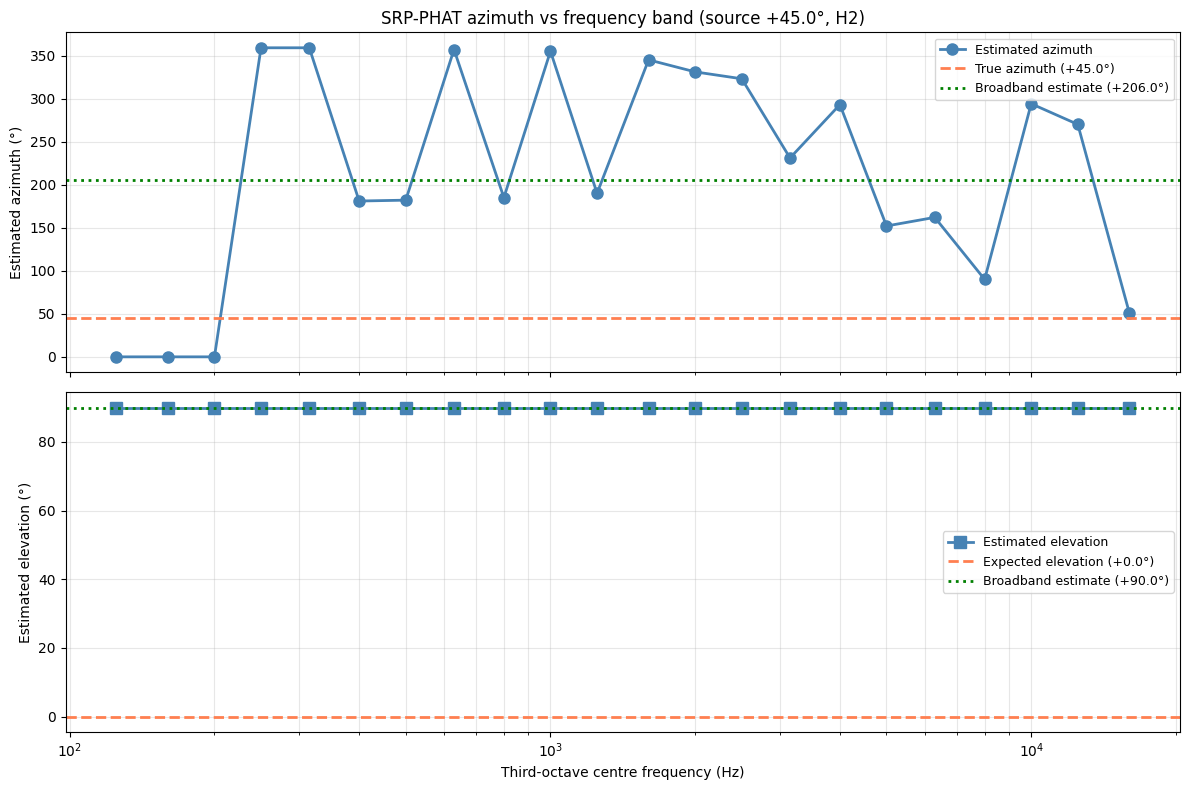

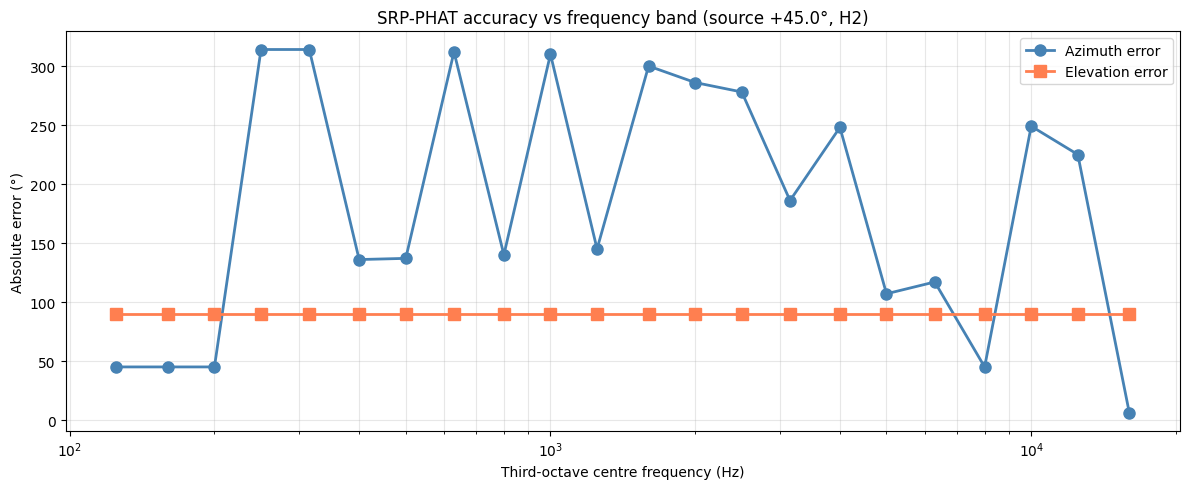

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

figures_dir = Path("figures")
figures_dir.mkdir(exist_ok=True)


def save_fig(fig, name):
    fig.savefig(figures_dir / f"{name}.png", dpi=200, bbox_inches='tight')
    fig.savefig(figures_dir / f"{name}.pdf", bbox_inches='tight')


def plot_srp_frequency_analysis(srp_results):
    true_az = srp_results['source_angle']
    expected_el = srp_results['expected_el']
    height = srp_results['height']
    
    az_broadband = srp_results['broadband']['az']
    el_broadband = srp_results['broadband']['el']
    
    bands = sorted(srp_results['per_band'].keys())
    az_estimates = [srp_results['per_band'][b]['az'] for b in bands]
    el_estimates = [srp_results['per_band'][b]['el'] for b in bands]
    az_errors    = [abs(srp_results['per_band'][b]['az_err']) for b in bands]
    el_errors    = [abs(srp_results['per_band'][b]['el_err']) for b in bands]


    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
    ax1.semilogx(bands, az_estimates, 'o-', color='steelblue', linewidth=2,
                 markersize=8, label='Estimated azimuth')
    ax1.axhline(true_az, color='coral', linestyle='--', linewidth=2,
                label=f'True azimuth ({true_az:+.1f}°)')
    ax1.axhline(az_broadband, color='green', linestyle=':', linewidth=2,
                label=f'Broadband estimate ({az_broadband:+.1f}°)')
    ax1.set_ylabel('Estimated azimuth (°)')
    ax1.set_title(f'SRP-PHAT azimuth vs frequency band '
                  f'(source {true_az:+.1f}°, {height})')
    ax1.grid(True, which='both', alpha=0.3)
    ax1.legend(loc='best', fontsize=9)

    ax2.semilogx(bands, el_estimates, 's-', color='steelblue', linewidth=2,
                 markersize=8, label='Estimated elevation')
    ax2.axhline(expected_el, color='coral', linestyle='--', linewidth=2,
                label=f'Expected elevation ({expected_el:+.1f}°)')
    ax2.axhline(el_broadband, color='green', linestyle=':', linewidth=2,
                label=f'Broadband estimate ({el_broadband:+.1f}°)')
    ax2.set_xlabel('Third-octave centre frequency (Hz)')
    ax2.set_ylabel('Estimated elevation (°)')
    ax2.grid(True, which='both', alpha=0.3)
    ax2.legend(loc='best', fontsize=9)

    plt.tight_layout()
    save_fig(fig, f'srp_freq_{height}_{int(true_az)}')
    plt.show()
    plt.close(fig)


    fig, ax = plt.subplots(figsize=(12, 5))
    ax.semilogx(bands, az_errors, 'o-', color='steelblue', linewidth=2,
                markersize=8, label='Azimuth error')
    ax.semilogx(bands, el_errors, 's-', color='coral', linewidth=2,
                markersize=8, label='Elevation error')
    ax.set_xlabel('Third-octave centre frequency (Hz)')
    ax.set_ylabel('Absolute error (°)')
    ax.set_title(f'SRP-PHAT accuracy vs frequency band '
                 f'(source {true_az:+.1f}°, {height})')
    ax.grid(True, which='both', alpha=0.3)
    ax.legend()
    plt.tight_layout()
    save_fig(fig, f'srp_freq_error_{height}_{int(true_az)}')
    plt.show()
    plt.close(fig)


plot_srp_frequency_analysis(srp_results)